<a href="https://colab.research.google.com/github/bjchris32/Jprotobuf-rpc-socket/blob/master/mnist_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
#hide
! [ -e /content ] && pip install -Uqq fastbook
import fastbook
fastbook.setup_book()

In [4]:
#hide
from fastai.vision.all import *
from fastbook import *

matplotlib.rc('image', cmap='Greys')

In [8]:
URLs.MNIST

'https://s3.amazonaws.com/fast-ai-imageclas/mnist_png.tgz'

## Loading MNIST

In [5]:
path = untar_data(URLs.MNIST)
#hide
Path.BASE_PATH = path

In [6]:
print(path.ls())
print((path/'training').ls().sorted())
print((path/'testing').ls().sorted())

[Path('training'), Path('testing')]
[Path('training/0'), Path('training/1'), Path('training/2'), Path('training/3'), Path('training/4'), Path('training/5'), Path('training/6'), Path('training/7'), Path('training/8'), Path('training/9')]
[Path('testing/0'), Path('testing/1'), Path('testing/2'), Path('testing/3'), Path('testing/4'), Path('testing/5'), Path('testing/6'), Path('testing/7'), Path('testing/8'), Path('testing/9')]


In [8]:
(path/'training').ls().sorted()[6:8]

(#2) [Path('training/6'),Path('training/7')]

### Show a test sample

In [11]:
len((path/'training'/'6').ls())
im6_path = (path/'training'/'6').ls()[0]
im6 = Image.open(im6_path)
im6

In [12]:
im6_t = tensor(im6)
df = pd.DataFrame(im6_t[4:15,4:22])
df.style.set_properties(**{'font-size':'6pt'}).background_gradient('Greys')

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
0,0,0,0,0,0,0,0,28,218,254,254,99,0,0,0,0,0,0
1,0,0,0,0,0,0,13,215,254,254,205,14,0,0,0,0,0,0
2,0,0,0,0,0,0,99,254,254,254,76,0,0,0,0,0,0,0
3,0,0,0,0,0,0,113,254,254,223,29,0,0,0,0,0,0,0
4,0,0,0,0,0,0,116,254,254,114,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,202,254,196,2,0,0,0,0,0,0,0,0
6,0,0,0,0,0,61,254,254,113,0,0,0,0,0,0,0,0,0
7,0,0,0,0,0,177,254,194,6,0,0,0,0,0,2,87,203,237
8,0,0,0,0,91,250,254,109,0,0,0,0,0,32,225,254,254,254
9,0,0,0,0,181,254,225,12,0,0,0,6,86,229,254,233,136,52


### Use the default `training` and `testing` path for training and validation(Incorrect implementation)

In [135]:
digits_training_tensors = [torch.stack([tensor(Image.open(o)) for o in digit_path.ls().sorted()]).float()/255 for digit_path in (path/'training').ls().sorted()]
digits_testing_tensors = [torch.stack([tensor(Image.open(o)) for o in digit_path.ls().sorted()]).float()/255 for digit_path in (path/'testing').ls().sorted()]

# test for only a few classes
# digits_training_tensors = [torch.stack([tensor(Image.open(o)) for o in digit_path.ls().sorted()]).float()/255 for digit_path in (path/'training').ls().sorted()[6:]]
# digits_testing_tensors = [torch.stack([tensor(Image.open(o)) for o in digit_path.ls().sorted()]).float()/255 for digit_path in (path/'testing').ls().sorted()[6:]]

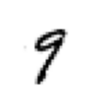

In [96]:
# check a sample
show_image(digits_training_tensors[-1][8]);

#### Build training dataset

In [137]:
# the textbook example only have two classes, how do we define the function to classify multiple classes
train_x = torch.cat(digits_training_tensors).view(-1, 28*28)
train_y = torch.cat([
  torch.full((len(digits_training_tensors[d]),), d, dtype=torch.long)
  for d in range(0, len(digits_training_tensors))
])

train_x.shape,train_y.shape

(torch.Size([60000, 784]), torch.Size([60000]))

In [100]:
train_dset = list(zip(train_x,train_y))
x,y = train_dset[-1]
x.shape,y.shape

(torch.Size([784]), torch.Size([]))

#### Build validation dataset

In [138]:
valid_x = torch.cat(digits_testing_tensors).view(-1, 28*28)
valid_y = torch.cat([
  torch.full((len(digits_testing_tensors[d]),), d, dtype=torch.long)
  for d in range(0, len(digits_testing_tensors))
])
print(valid_x.shape,valid_y.shape)
valid_dset = list(zip(valid_x,valid_y))

torch.Size([10000, 784]) torch.Size([10000])


In [102]:
count_valid_digit_len = [len(digits_testing_tensors[d]) for d in range(0, len(digits_testing_tensors))]
print(count_valid_digit_len)
sum(count_valid_digit_len)

[958, 1028, 974, 1009]


3969

### Split training dataset from `training` path into training and validation dataset(Correct implementation)

In [151]:
# only use training path for training and validation
train_path = (path/'training').ls().sorted()
all_labeled_image_tensors = [(tensor(Image.open(o)), int(path.name)) for path in train_path for o in path.ls()]
np.random.shuffle(all_labeled_image_tensors)

# split the training and validation dataset
training_valid_split_index = math.floor(len(all_labeled_image_tensors) * 0.9)
train, valid = all_labeled_image_tensors[:training_valid_split_index], all_labeled_image_tensors[training_valid_split_index:]

train_x = torch.cat([train[i][0].view(-1, 784).float()/255 for i in range(len(train))])
train_y = tensor([train[i][1] for i in range(len(train))])
train_dset = list(zip(train_x, train_y))

valid_x = torch.cat([valid[i][0].view(-1, 784).float()/255 for i in range(len(valid))])
valid_y = tensor([valid[i][1] for i in range(len(valid))])
valid_dset = list(zip(valid_x, valid_y))

In [150]:
print(len(train), len(valid))

54000 6000


## Training the model

### Define loss function

In [152]:
# Some items to work on:
# simplify the passing of weight and bias among functions

def init_params(size, std=1.0): return (torch.randn(size)*std).requires_grad_()

def linear1(xb, weights, bias): return xb@weights + bias

# sigmoid is for binary probs (squash a single logit to (0,1)).
# softmax is for multi-class probs (normalize many logits into a distribution).
def mnist_loss(predictions, targets):
    # sol1: self-implemented entropy function
    softmax_predictions = torch.softmax(predictions, dim=1)
    target_class_probs = softmax_predictions[torch.arange(len(targets)), targets]
    # use negative log likelihood to make penalties
    # if highest probability is on the correct label, it has less penalties
    # if highest is on the wrong label, it has most penalties
    return -torch.log(target_class_probs + 1e-9).mean()

    # sol2: pytorch default cross_entropy function
    # loss = F.cross_entropy(predictions, targets)
    # return loss

### Training for one time

In [156]:
train_dl = DataLoader(train_dset, batch_size=256)
xb,yb = first(train_dl)
print("train dl:", xb.shape,yb.shape)

valid_dl = DataLoader(valid_dset, batch_size=256)
xb,yb = first(train_dl)
print("valid dl:", xb.shape,yb.shape)

train dl: torch.Size([256, 784]) torch.Size([256])
valid dl: torch.Size([256, 784]) torch.Size([256])


#### try a small batch prediction

In [21]:
batch = train_x[:4]
batch.shape

torch.Size([4, 784])

In [77]:
weights = init_params((28*28, len(digits_testing_tensors)))
bias = init_params(len(digits_testing_tensors))

preds = linear1(batch, weights, bias)
preds

tensor([[ -3.9230,   7.4609,  -3.5901],
        [ -2.9559, -10.6990,  -0.8879],
        [-11.3055,  10.1587, -13.1680],
        [ -9.5636,  10.4412,  -9.4645]], grad_fn=<AddBackward0>)

In [78]:
softmax_predictions = torch.softmax(preds, dim=0)
print(softmax_predictions)
softmax_predictions.shape

tensor([[2.7516e-01, 2.8138e-02, 6.2833e-02],
        [7.2369e-01, 3.6519e-10, 9.3699e-01],
        [1.7116e-04, 4.1776e-01, 4.3507e-06],
        [9.7699e-04, 5.5410e-01, 1.7658e-04]], grad_fn=<SoftmaxBackward0>)


torch.Size([4, 3])

In [79]:
row_indices = torch.arange(len(train_y[:4]))
correct_class_probs = softmax_predictions[row_indices, train_y[:4]]
print(correct_class_probs)
loss = -torch.log(correct_class_probs).mean()
print("negative log", loss)

tensor([2.7516e-01, 7.2369e-01, 1.7116e-04, 9.7699e-04], grad_fn=<IndexBackward0>)
negative log tensor(4.3044, grad_fn=<NegBackward0>)


In [80]:
# get gradient
loss.backward()

In [81]:
weights.grad.shape,weights.grad.mean(),bias.grad

(torch.Size([784, 3]),
 tensor(0.0004),
 tensor([-1.4901e-08,  0.0000e+00,  0.0000e+00]))

In [82]:
# step the weights and bias with a step of gradient
weights.data -= weights.grad * 0.1
bias.data -= bias.grad * 0.1

weights.grad.zero_();
bias.grad.zero_();

#### put gradient calculation into method

In [28]:
def calc_grad(xb, yb, model, weights, bias):
    preds = model(xb, weights, bias)
    loss = mnist_loss(preds, yb)
    loss.backward()


#### Show the metrics after training

In [29]:
def batch_accuracy(xb, yb):
    # print("xb.shape:", xb.shape)
    # softmax_preds = torch.softmax(xb, dim=1)
    # prob, prob_index = torch.max(softmax_preds, dim=1)
    # # print("prob_index = ", prob_index)
    # correct = prob_index == yb

    # print("torch.argmax(xb, dim=1) = ", torch.argmax(xb, dim=1))
    correct = torch.argmax(xb, dim=1) == yb
    return correct.float().mean()

In [30]:
def validate_epoch(model, weights, bias):
    accs = [batch_accuracy(model(xb, weights, bias), yb) for xb,yb in valid_dl]
    return round(torch.stack(accs).mean().item(), 4)

In [83]:
batch_accuracy(linear1(batch, weights, bias), train_y[:4])

tensor(0.)

In [86]:
calc_grad(batch, train_y[:4], linear1, weights, bias)
weights.grad.mean(),bias.grad

weights.data -= weights.grad * 0.1
bias.data -= bias.grad * 0.1

weights.grad.zero_();
bias.grad.zero_();

In [87]:
batch_accuracy(linear1(batch, weights, bias), train_y[:4])

tensor(1.)

### Training all batch

In [44]:
def train_epoch(model, lr, params, weights, bias):
    for xb,yb in train_dl:
        calc_grad(xb, yb, model, weights, bias)
        for p in params:
            p.data -= p.grad*lr
            p.grad.zero_()

#### Train with loops

In [157]:
weights = init_params((28*28, 10))
bias = init_params(10)

In [158]:
lr = 0.1
params = weights,bias

In [159]:
for i in range(20):
    old_weights = params[0].clone()
    train_epoch(linear1, lr, params, weights, bias)
    print((params[0] - old_weights).norm())
    print(validate_epoch(linear1, weights, bias), end=' ')

tensor(10.0930, grad_fn=<LinalgVectorNormBackward0>)
0.6177 tensor(3.6369, grad_fn=<LinalgVectorNormBackward0>)
0.7122 tensor(2.3331, grad_fn=<LinalgVectorNormBackward0>)
0.7502 tensor(1.7631, grad_fn=<LinalgVectorNormBackward0>)
0.7716 tensor(1.4396, grad_fn=<LinalgVectorNormBackward0>)
0.7901 tensor(1.2270, grad_fn=<LinalgVectorNormBackward0>)
0.8051 tensor(1.0759, grad_fn=<LinalgVectorNormBackward0>)
0.8133 tensor(0.9630, grad_fn=<LinalgVectorNormBackward0>)
0.8218 tensor(0.8751, grad_fn=<LinalgVectorNormBackward0>)
0.8283 tensor(0.8048, grad_fn=<LinalgVectorNormBackward0>)
0.8353 tensor(0.7472, grad_fn=<LinalgVectorNormBackward0>)
0.8383 tensor(0.6988, grad_fn=<LinalgVectorNormBackward0>)
0.8423 tensor(0.6575, grad_fn=<LinalgVectorNormBackward0>)
0.8457 tensor(0.6218, grad_fn=<LinalgVectorNormBackward0>)
0.8493 tensor(0.5906, grad_fn=<LinalgVectorNormBackward0>)
0.8519 tensor(0.5630, grad_fn=<LinalgVectorNormBackward0>)
0.8534 tensor(0.5384, grad_fn=<LinalgVectorNormBackward0>)
0.8

The accuracy was too low at around 0.7 after 20 rounds of training.
It is expected to be 80% accuracy after 1 round.

After comparing what other people are doing, I found my script to train the model is correct. Why the original implementation did not reach the 80% accuracy is because the dataset I used in both training and validation. If I split the same training path into two folds with 90% for training and 10% for validation, instead of using training path for training and testing path for validation, I could also reach 80% accuracy.

### Training with a learner class

In [118]:
# add ReLu
simple_net = nn.Sequential(
    nn.Linear(28 * 28, 30),
    nn.ReLU(),
    nn.Linear(30, 10)
)

In [119]:
learner_dls = DataLoaders(train_dl, valid_dl)

In [120]:
learn = Learner(learner_dls, simple_net, opt_func=SGD, loss_func=mnist_loss, metrics=batch_accuracy)

In [121]:
learn.fit(20, 0.1)

epoch,train_loss,valid_loss,batch_accuracy,time
0,0.549547,0.432215,0.883083,00:00
1,0.373474,0.354747,0.900417,00:00
2,0.331022,0.325144,0.909000,00:00
3,0.307498,0.306114,0.913833,00:00
4,0.290028,0.290920,0.918500,00:00
5,0.275356,0.277959,0.920917,00:00
6,0.262267,0.266355,0.923417,00:00
7,0.250430,0.255700,0.925250,00:01
8,0.239642,0.245633,0.927917,00:01
9,0.229841,0.236559,0.930917,00:01


The accuracy could be boosted from 0.8 to 0.9.

### Export the trained model

## References:
- https://medium.com/@jackdriscoll_90855/fast-ai-chapter-4-full-mnist-challenge-8558b1e0564a
